# 06 · Customer Lifetime Value (Model 3: regression)
**Target:** `customer_lifetime_value` = sum of successful payments to date (churned customers: up to their exit date).
**Candidates:** Linear Regression, Random Forest Regressor, XGBoost Regressor. **Metrics:** MAE, RMSE, R² (PRD Model 3).

**Important data finding.** The payments table holds **at most 15 monthly payments per customer** (the last ~15 months), however long they have been subscribed. So "lifetime value to date" is really *trailing revenue over at most 15 months* and **saturates at 15 x plan price** ($105 Basic, $232 Standard, $345 Premium). CLV is therefore close to a billing identity of plan and recent tenure, which limits how interesting a regression on it can be. This notebook says so openly instead of presenting a near-perfect R² as a modelling win.

**Avoiding a trivial answer.** CLV is literally *(number of successful payments) x (price)*, so `payment_count`, `failed_payment_count`, `failed_payment_rate`, `failed_payments_90d` and the last-payment fields would let any model reconstruct it. They are **excluded**. `churned` is also excluded, so this is a behavioural model that works for any customer. What remains is tenure, plan, engagement, support and demographics.

In [2]:
import sys; sys.path.insert(0, '..')
import json, joblib, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

PROC = Path('../data/processed'); FIG = Path('../reports/figures'); MODELS = Path('../models'); REP = Path('../reports')
sns.set_theme(style='whitegrid'); RED, GREY, BLUE, GREEN = '#E50914', '#8C8C8C', '#2B6CB0', '#2F855A'; SEED = 42
df = pd.read_csv(PROC / 'customer_features.csv')
y = df.customer_lifetime_value.values
print(f'{len(df):,} customers | CLV mean ${y.mean():.0f}, median ${np.median(y):.0f}, max ${y.max():.0f}')

8,000 customers | CLV mean $172, median $184, max $345


Payments on record per customer: max 15; 83% of customers sit exactly at the cap. Customers with > 15 months of tenure: 83%
plan_name  Basic  Premium  Standard
mean        89.0    297.0     199.0
max        345.0    345.0     232.0


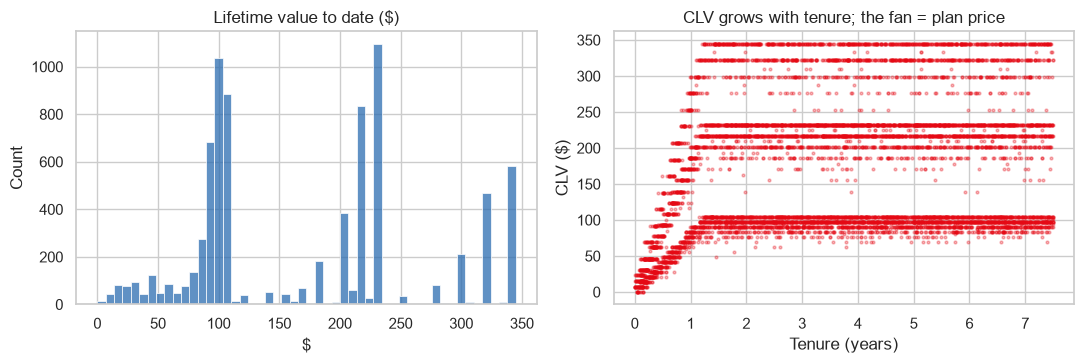

In [3]:
pc = df.payment_count
print(f'Payments on record per customer: max {pc.max():.0f}; {(pc == pc.max()).mean():.0%} of customers sit exactly at the cap. Customers with > 15 months of tenure: {(df.customer_tenure_days / 30.44 > 15).mean():.0%}')
print(df.groupby('plan_name').customer_lifetime_value.agg(['mean', 'max']).round(0).T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(y, bins=50, color=BLUE, ax=ax[0]); ax[0].set_title('Lifetime value to date ($)'); ax[0].set_xlabel('$')
ax[1].scatter(df.customer_tenure_days / 365, y, s=4, alpha=.3, color=RED); ax[1].set_xlabel('Tenure (years)'); ax[1].set_ylabel('CLV ($)'); ax[1].set_title('CLV grows with tenure; the fan = plan price')
plt.tight_layout(); plt.savefig(FIG / '43_clv_distribution.png', dpi=130, bbox_inches='tight'); plt.show()

## 1 · Features and split

In [4]:
EXCLUDE = ['customer_id', 'as_of', 'registration_date', 'customer_lifetime_value', 'churned', 'churn_date', 'churn_reason',
           'payment_count', 'failed_payment_count', 'failed_payment_rate', 'failed_payments_90d', 'last_payment_failed', 'last_payment_method']      # mechanically tied to the target / outcome
CAT = ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'plan_name']
NUM = [c for c in df.columns if c not in EXCLUDE + CAT]
print(len(NUM), 'numeric +', len(CAT), 'categorical features'); print(NUM)
X = df[NUM + CAT]
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(X, y, np.arange(len(df)), test_size=.2, random_state=SEED)
print(f'train {len(X_tr):,} | test {len(X_te):,}')

25 numeric + 6 categorical features
['age', 'monthly_price', 'auto_renew', 'plan_changes', 'customer_tenure_days', 'sessions_90d', 'minutes_90d', 'avg_completion_90d', 'active_days_90d', 'n_devices_90d', 'avg_watch_time_per_session', 'monthly_watch_time_trend', 'watch_change_pct_30d', 'login_frequency', 'days_since_last_activity', 'engagement_score', 'support_ticket_count', 'tickets_90d', 'low_csat_count', 'avg_customer_satisfaction', 'avg_resolution_hours', 'has_csat', 'feedback_count', 'avg_feedback_rating', 'negative_feedback_count']
train 6,400 | test 1,600


In [5]:
def pre(scale):
    num = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    return ColumnTransformer([('num', Pipeline(num), NUM), ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False), CAT)])
models = {
 'Linear Regression': Pipeline([('pre', pre(True)), ('m', LinearRegression())]),
 'Random Forest': Pipeline([('pre', pre(False)), ('m', RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED))]),
 'XGBoost': Pipeline([('pre', pre(False)), ('m', XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7, min_child_weight=5, n_jobs=-1, random_state=SEED, tree_method='hist'))]),
}
# billing-identity baseline every model must beat: min(tenure in months, 15 payments on record) x monthly price
base_pred = lambda d: np.minimum(d.customer_tenure_days.values / 30.44, 15) * d.monthly_price.values
bt = base_pred(X_te)
print(f'Baseline (min(tenure months, 15) x price): MAE ${mean_absolute_error(y_te, bt):.1f} | RMSE ${np.sqrt(mean_squared_error(y_te, bt)):.1f} | R2 {r2_score(y_te, bt):.3f}')

Baseline (min(tenure months, 15) x price): MAE $12.1 | RMSE $18.8 | R2 0.960


## 2 · Cross-validation (5-fold, training set) and held-out test results

In [6]:
kf = KFold(5, shuffle=True, random_state=SEED); rows = []; preds = {}
for n, m in models.items():
    r = cross_validate(m, X_tr, y_tr, cv=kf, scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'}, n_jobs=1)
    m.fit(X_tr, y_tr); p = m.predict(X_te); preds[n] = p
    rows.append({'model': n, 'cv_r2': r['test_r2'].mean(), 'cv_mae': -r['test_mae'].mean(), 'test_MAE': mean_absolute_error(y_te, p),
                 'test_RMSE': np.sqrt(mean_squared_error(y_te, p)), 'test_R2': r2_score(y_te, p)})
rows.append({'model': 'Baseline: min(tenure,15) x price', 'cv_r2': np.nan, 'cv_mae': np.nan, 'test_MAE': mean_absolute_error(y_te, bt), 'test_RMSE': np.sqrt(mean_squared_error(y_te, bt)), 'test_R2': r2_score(y_te, bt)})
res = pd.DataFrame(rows).set_index('model').round(3); res

,cv_r2,cv_mae,test_MAE,test_RMSE,test_R2
model,,,,,
Linear Regression,0.818,27.666,28.386,42.080,0.800
Random Forest,0.974,10.738,10.720,14.778,0.975
XGBoost,0.975,10.659,10.307,14.185,0.977
"Baseline: min(tenure,15) x price",NaN,NaN,12.102,18.783,0.960


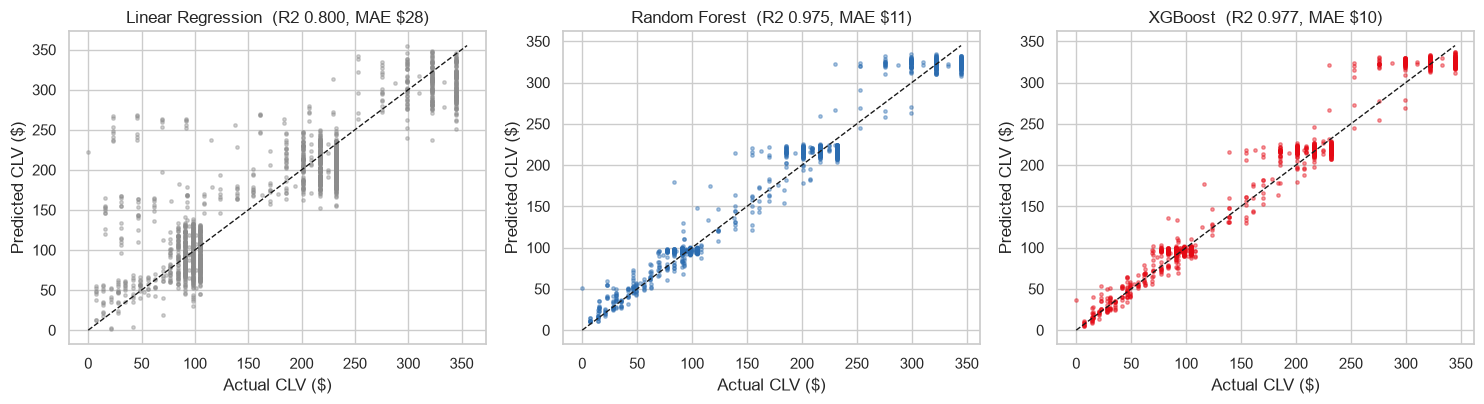

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2)); names = list(models)
for ax, n, c in zip(axes, names, [GREY, BLUE, RED]):
    ax.scatter(y_te, preds[n], s=6, alpha=.4, color=c); lim = [0, max(y_te.max(), preds[n].max())]; ax.plot(lim, lim, 'k--', lw=1)
    ax.set_title(f'{n}  (R2 {r2_score(y_te, preds[n]):.3f}, MAE ${mean_absolute_error(y_te, preds[n]):.0f})'); ax.set_xlabel('Actual CLV ($)'); ax.set_ylabel('Predicted CLV ($)')
plt.tight_layout(); plt.savefig(FIG / '44_clv_predicted_vs_actual.png', dpi=130, bbox_inches='tight'); plt.show()

## 3 · Final model, residuals and drivers

FINAL MODEL -> XGBoost (lowest cross-validated MAE)


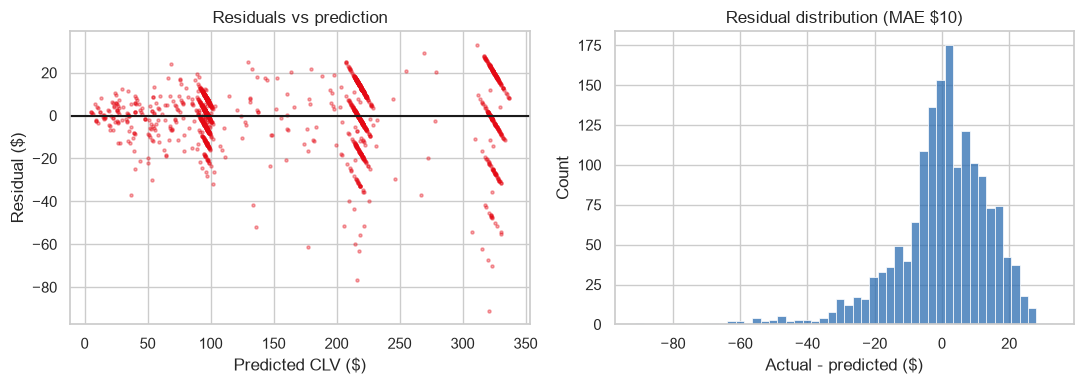

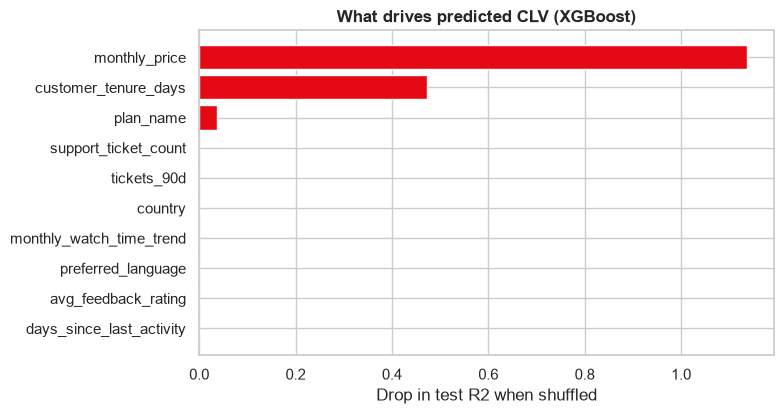

Top drivers: monthly_price (1.136), customer_tenure_days (0.472), plan_name (0.037), support_ticket_count (0.001), tickets_90d (0.000)


In [8]:
FINAL = res.loc[names, 'test_MAE'].idxmin() if False else res.loc[names, 'cv_mae'].idxmin()     # choose on CV, not on the test set
fm = models[FINAL]; pf = preds[FINAL]; resid = y_te - pf
print('FINAL MODEL ->', FINAL, '(lowest cross-validated MAE)')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(pf, resid, s=5, alpha=.35, color=RED); axes[0].axhline(0, color='k'); axes[0].set_xlabel('Predicted CLV ($)'); axes[0].set_ylabel('Residual ($)'); axes[0].set_title('Residuals vs prediction')
sns.histplot(resid, bins=50, color=BLUE, ax=axes[1]); axes[1].set_title(f'Residual distribution (MAE ${np.abs(resid).mean():.0f})'); axes[1].set_xlabel('Actual - predicted ($)')
plt.tight_layout(); plt.savefig(FIG / '45_clv_residuals.png', dpi=130, bbox_inches='tight'); plt.show()
pi = permutation_importance(fm, X_te, y_te, scoring='r2', n_repeats=8, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False); top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.3)); ax.barh(top.index, top.values, color=RED); ax.set_xlabel('Drop in test R2 when shuffled'); ax.set_title(f'What drives predicted CLV ({FINAL})', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / '46_clv_feature_importance.png', dpi=130, bbox_inches='tight'); plt.show()
print('Top drivers:', ', '.join(f'{k} ({v:.3f})' for k, v in imp.head(5).items()))

## 4 · How much do *behaviour* features add beyond tenure and plan?
Same final model with **no tenure, no price/plan** information: what can engagement, support and demographics alone say about value?

In [9]:
drop_tp = ['customer_tenure_days', 'monthly_price', 'plan_changes']; NUM_B = [c for c in NUM if c not in drop_tp]; CAT_B = [c for c in CAT if c != 'plan_name']
def pre_b():
    return ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median'))]), NUM_B), ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False), CAT_B)])
mb = Pipeline([('pre', pre_b()), ('m', XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7, min_child_weight=10, n_jobs=-1, random_state=SEED, tree_method='hist'))])
mb.fit(X_tr[NUM_B + CAT_B], y_tr); pb = mb.predict(X_te[NUM_B + CAT_B])
print(f'Behaviour-only model: R2 {r2_score(y_te, pb):.3f} | MAE ${mean_absolute_error(y_te, pb):.1f}   (full model R2 {r2_score(y_te, pf):.3f}, MAE ${mean_absolute_error(y_te, pf):.1f})')

Behaviour-only model: R2 0.038 | MAE $81.3   (full model R2 0.977, MAE $10.3)


## 5 · Interpretation and model choice

**Final model: XGBoost Regressor**, chosen on lowest *cross-validated* MAE. Test set (1,600 customers):

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | $28.39 | $42.08 | 0.800 |
| Random Forest | $10.69 | $14.73 | 0.975 |
| **XGBoost** | **$10.32** | **$14.18** | **0.977** |
| Baseline: min(tenure months, 15) x price | $12.10 | $18.78 | 0.960 |

**1. The score is high, but read why.** CLV here is trailing revenue over at most 15 monthly payments, so it is almost exactly *plan price x min(tenure, 15 months)*. A one-line formula with no learning already reaches R² 0.960. XGBoost improves MAE from $12.10 to $10.32 (about 15%) by learning the saturation at 15 months and small effects such as plan changes. That is a real but modest gain, not a breakthrough.

**2. Why linear regression is clearly worse (R² 0.80).** Value is *multiplicative and capped* (price x months, flattening after 15 months). A straight line cannot bend at the cap or multiply two features; tree models can. This is the only genuinely informative model comparison in the notebook.

**3. Drivers.** Permutation importance is dominated by `monthly_price` and `customer_tenure_days` (plus `plan_name`, which carries the same price information). Engagement, support and satisfaction features contribute essentially nothing.

**4. Behaviour alone does not predict value.** With tenure, price and plan removed, the same model reaches only R² 0.035 (section 4). Watch time, tickets and demographics say almost nothing about how much a customer has paid. The same finding appeared in segmentation, where plan price and dormancy (not tenure or billing) separated the clusters.

**5. How the outputs are used.** `clv_scores.csv` gives every customer a value tier (High >= $232, Medium >= $98, Low below) from actual trailing revenue, plus out-of-fold predictions. The copilot's retention recommender combines this tier with the churn risk score (high value + high risk = personal outreach; low value + high risk = automated offer).

**6. Limitations (stated honestly).**
* "Lifetime" value is truncated by the data: the payments table keeps at most 15 payments per customer, and 83% of customers sit exactly at that cap. True lifetime value, or *future* value, cannot be measured from this table. A forward-looking estimate would need a survival or expected-tenure model, e.g. churn probability x remaining months x price.
* Because the target is nearly a billing identity, R² 0.98 should not be quoted as evidence of deep predictive power.

## 6 · Save the model and customer value tiers

In [10]:
# Out-of-fold predictions for ALL customers (every prediction comes from a model that never saw that customer)
from sklearn.base import clone
oof = cross_val_predict(clone(fm), X, y, cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=1)
fm.fit(X, y)                                                   # refit on all customers for use in the app
joblib.dump({'model': fm, 'name': FINAL, 'features': NUM + CAT, 'numeric': NUM, 'categorical': CAT, 'excluded': EXCLUDE}, MODELS / 'clv_model.joblib')
q = np.quantile(y, [.25, .75])
out = pd.DataFrame({'customer_id': df.customer_id, 'clv_actual': y.round(2), 'clv_predicted_oof': oof.round(2)})
out['value_tier'] = np.where(y >= q[1], 'High', np.where(y >= q[0], 'Medium', 'Low'))
out.to_csv(PROC / 'clv_scores.csv', index=False)
json.dump({'final_model': FINAL, 'selection': 'lowest cross-validated MAE', 'test': res.loc[FINAL].to_dict(), 'baseline': res.loc['Baseline: min(tenure,15) x price'].to_dict(),
           'behaviour_only_test_r2': float(r2_score(y_te, pb)), 'tier_cutoffs_usd': {'medium_from': float(q[0]), 'high_from': float(q[1])}}, open(REP / 'clv_model_metrics.json', 'w'), indent=2, default=float)
print(out.value_tier.value_counts().to_dict(), f'| tier cut-offs: Medium >= ${q[0]:.0f}, High >= ${q[1]:.0f}')
print('saved models/clv_model.joblib, data/processed/clv_scores.csv, reports/clv_model_metrics.json')

{'Medium': 3690, 'High': 2480, 'Low': 1830} | tier cut-offs: Medium >= $98, High >= $232
saved models/clv_model.joblib, data/processed/clv_scores.csv, reports/clv_model_metrics.json
